<a href="https://colab.research.google.com/github/Fyyskie/TUBES_KB_2026_KelasB_Kelompok04/blob/main/W13_GA_FEATURE_SELECTION_KEL4/TUBES_KECEBUT_KEL4_W13_GA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROGRESS WEEK 13-Genetic Algorithm dan feature/variable selection**

## Implementasikan encoding chromosome, objective/fitness, selection, crossover, mutation, elitism dan stopping criterion. Lakukan GA pada fitur/sensor/lag, lalu latih NN pada subset hasil GA dengan protokol split tetap.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membaca kelima dataset
df_2011 = pd.read_csv('gt_2011.csv')
df_2012 = pd.read_csv('gt_2012.csv')
df_2013 = pd.read_csv('gt_2013.csv')
df_2014 = pd.read_csv('gt_2014.csv')
df_2015 = pd.read_csv('gt_2015.csv')

# 2. Menggabungkan data secara berurutan (Chronological)
df_all = pd.concat([df_2011, df_2012, df_2013, df_2014, df_2015], ignore_index=True)

print(f"Total baris data: {df_all.shape[0]}, Total kolom: {df_all.shape[1]}")
display(df_all.head())

Total baris data: 36733, Total kolom: 11


,AT,AP,AH,AFDP,GTEP,TIT,TAT,TEY,CDP,CO,NOX
0,4.5878,1018.7,83.675,3.5758,23.979,1086.2,549.83,134.67,11.898,0.32663,81.952
1,4.2932,1018.3,84.235,3.5709,23.951,1086.1,550.05,134.67,11.892,0.44784,82.377
2,3.9045,1018.4,84.858,3.5828,23.990,1086.5,550.19,135.10,12.042,0.45144,83.776
3,3.7436,1018.3,85.434,3.5808,23.911,1086.5,550.17,135.03,11.990,0.23107,82.505
4,3.7516,1017.8,85.182,3.5781,23.917,1085.9,550.00,134.67,11.910,0.26747,82.028


# **Tahap Pertama: Sel Preprocessing (Split & Scaling).**

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_all.drop(columns=['CO', 'NOX'])
y = df_all[['CO', 'NOX']]

# 1. Kunci 20% data sebagai Test Set (tidak boleh disentuh GA)
X_train_full, X_test, y_train_full, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Pecah 80% sisanya menjadi Train (64%) dan Validation (16%) khusus untuk GA
X_train, X_val, y_train, y_val = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)

# 3. Scaling (fit HANYA pada X_train dan y_train)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_val_scaled   = scaler_X.transform(X_val)
X_test_scaled  = scaler_X.transform(X_test)

y_train_scaled = scaler_y.fit_transform(y_train)
y_val_scaled   = scaler_y.transform(y_val)
y_test_scaled  = scaler_y.transform(y_test)

print(f"Train: {X_train_scaled.shape} | Val (GA): {X_val_scaled.shape} | Test (Final): {X_test_scaled.shape}")

Train: (23508, 9) | Val (GA): (5878, 9) | Test (Final): (7347, 9)


#**Tahap Kedua: Sel Utama: Genetic Algorithm Dengan Beberapa SEED (Seleksi Fitur)**

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Seed 15 selesai | Fitness: 0.79717 | Val MSE: 0.24778 | Fitur (6): ['AT', 'AP', 'AFDP', 'TIT', 'TAT', 'CDP']


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Seed 1 selesai | Fitness: 0.80914 | Val MSE: 0.22810 | Fitur (7): ['AT', 'AH', 'AFDP', 'TIT', 'TAT', 'TEY', 'CDP']


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Seed 16 selesai | Fitness: 0.80782 | Val MSE: 0.23123 | Fitur (6): ['AT', 'AH', 'AFDP', 'TIT', 'TAT', 'TEY']


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py

Seed 91 selesai | Fitness: 0.80971 | Val MSE: 0.22724 | Fitur (7): ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT']


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (30) reached and the optimization hasn't converged yet.
  warnings.warn(


,Seed,Jumlah Fitur,Fitur Terpilih,Best Fitness,Val MSE
0,15,6,"AT, AP, AFDP, TIT, TAT, CDP",0.79717,0.24778
1,1,7,"AT, AH, AFDP, TIT, TAT, TEY, CDP",0.80914,0.22810
2,16,6,"AT, AH, AFDP, TIT, TAT, TEY",0.80782,0.23123
3,91,7,"AT, AP, AH, AFDP, GTEP, TIT, TAT",0.80971,0.22724


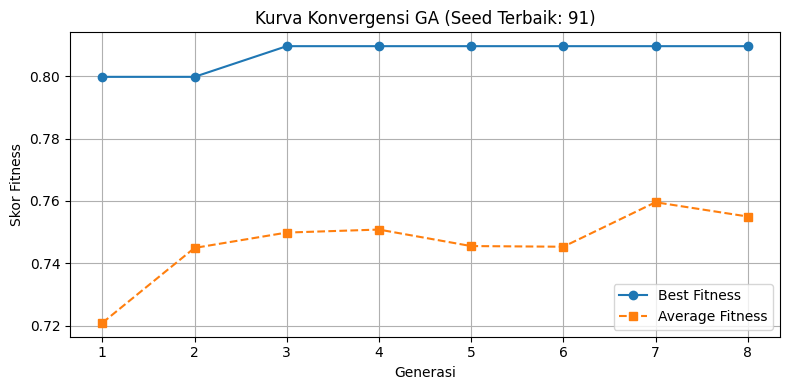

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

feature_names = ['AT', 'AP', 'AH', 'AFDP', 'GTEP', 'TIT', 'TAT', 'TEY', 'CDP']
NUM_FEATURES = len(feature_names)

def hitung_fitness(kromosom, X_tr, y_tr, X_v, y_v, alpha=0.01):
    selected_idx = [i for i, bit in enumerate(kromosom) if bit == 1]
    if len(selected_idx) == 0:
        return 0.0, 999.0
    model_eval = MLPRegressor(hidden_layer_sizes=(32, 16), max_iter=30, random_state=42, early_stopping=True)
    model_eval.fit(X_tr[:, selected_idx], y_tr)
    mse = mean_squared_error(y_v, model_eval.predict(X_v[:, selected_idx]))
    skor_biaya = mse + (alpha * (len(selected_idx) / NUM_FEATURES))
    return 1.0 / (1.0 + skor_biaya), mse

def jalankan_ga(seed, pop_size=10, generations=8, prob_c=0.8, prob_m=0.1):
    np.random.seed(seed)
    populasi = []
    for _ in range(pop_size):
        ind = np.random.randint(0, 2, size=NUM_FEATURES).tolist()
        if sum(ind) == 0: ind[np.random.randint(0, NUM_FEATURES)] = 1
        populasi.append(ind)

    best_hist, avg_hist = [], []
    best_krom, best_fit, best_mse = None, -1.0, 999.0

    for gen in range(generations):
        fits, mses = [], []
        for ind in populasi:
            f, m = hitung_fitness(ind, X_train_scaled, y_train_scaled, X_val_scaled, y_val_scaled)
            fits.append(f); mses.append(m)

        idx = np.argmax(fits)
        if fits[idx] > best_fit:
            best_fit, best_mse, best_krom = fits[idx], mses[idx], populasi[idx].copy()

        best_hist.append(fits[idx])
        avg_hist.append(np.mean(fits))

        pop_baru = [populasi[idx].copy()] # Elitism
        while len(pop_baru) < pop_size:
            # Tournament Selection
            p1 = populasi[np.random.choice(pop_size, 3, replace=False)[np.argmax([fits[i] for i in np.random.choice(pop_size, 3, replace=False)])]].copy()
            p2 = populasi[np.random.choice(pop_size, 3, replace=False)[np.argmax([fits[i] for i in np.random.choice(pop_size, 3, replace=False)])]].copy()
            # Crossover
            if np.random.rand() < prob_c:
                t = np.random.randint(1, NUM_FEATURES)
                c1, c2 = p1[:t] + p2[t:], p2[:t] + p1[t:]
            else:
                c1, c2 = p1.copy(), p2.copy()
            # Mutasi
            for c in [c1, c2]:
                for i in range(NUM_FEATURES):
                    if np.random.rand() < prob_m: c[i] = 1 - c[i]
                if sum(c) == 0: c[np.random.randint(0, NUM_FEATURES)] = 1
                if len(pop_baru) < pop_size: pop_baru.append(c)
        populasi = pop_baru

    return best_krom, best_fit, best_mse, best_hist, avg_hist

# Uji 4 Seed berbeda
seeds = [15, 1, 16, 91]
hasil_seeds = []
best_global_fit = -1.0
best_global_data = None

for s in seeds:
    krom, fit, mse, b_hist, a_hist = jalankan_ga(seed=s)
    fitur_aktif = [feature_names[i] for i, b in enumerate(krom) if b == 1]
    hasil_seeds.append({
        'Seed': s, 'Jumlah Fitur': len(fitur_aktif),
        'Fitur Terpilih': ', '.join(fitur_aktif),
        'Best Fitness': round(fit, 5), 'Val MSE': round(mse, 5)
    })
    print(f"Seed {s} selesai | Fitness: {fit:.5f} | Val MSE: {mse:.5f} | Fitur ({len(fitur_aktif)}): {fitur_aktif}")
    if fit > best_global_fit:
        best_global_fit = fit
        best_global_data = (s, krom, fitur_aktif, b_hist, a_hist)

# Tabel Bukti Multi-Seed
df_seeds = pd.DataFrame(hasil_seeds)
display(df_seeds)

# Plot Konvergensi Seed Terbaik
s_best, best_overall_kromosom, fitur_ga, b_hist, a_hist = best_global_data
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(b_hist) + 1), b_hist, marker='o', label='Best Fitness')
plt.plot(range(1, len(a_hist) + 1), a_hist, marker='s', linestyle='--', label='Average Fitness')
plt.title(f'Kurva Konvergensi GA (Seed Terbaik: {s_best})')
plt.xlabel('Generasi'); plt.ylabel('Skor Fitness'); plt.legend(); plt.grid(True)
plt.tight_layout(); plt.savefig('ga_convergence.png', dpi=150); plt.show()

# **Perbandingan Baseline NN vs GA+NN*

In [4]:
import time, joblib
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def latih_dan_evaluasi(X_tr, y_tr, X_v, y_v, X_te, y_te_asli, nama_model):
    tf.random.set_seed(42)
    model = Sequential([
        Dense(64, activation='relu', input_shape=(X_tr.shape[1],)),
        Dense(32, activation='relu'),
        Dense(16, activation='relu'),
        Dense(2, activation='linear')
    ])
    model.compile(optimizer='adam', loss='mse')

    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_v, y_v), epochs=50, batch_size=32, verbose=0)
    durasi = time.time() - t0

    # Evaluasi pada Test Set (skala asli)
    y_pred = scaler_y.inverse_transform(model.predict(X_te, verbose=0))
    return {
        'Model': nama_model,
        'Jumlah Fitur': X_tr.shape[1],
        'Waktu Latih (detik)': round(durasi, 2),
        'Val Loss (MSE)': round(min(hist.history['val_loss']), 4),
        'CO RMSE': round(np.sqrt(mean_squared_error(y_te_asli[:, 0], y_pred[:, 0])), 4),
        'CO R²': round(r2_score(y_te_asli[:, 0], y_pred[:, 0]), 4),
        'NOx RMSE': round(np.sqrt(mean_squared_error(y_te_asli[:, 1], y_pred[:, 1])), 4),
        'NOx R²': round(r2_score(y_te_asli[:, 1], y_pred[:, 1]), 4)
    }, model

# 1. Baseline NN (9 Fitur)
res_base, _ = latih_dan_evaluasi(X_train_scaled, y_train_scaled, X_val_scaled, y_val_scaled, X_test_scaled, y_test.values, 'Baseline NN (9 Fitur)')

# 2. GA + NN (Fitur Terpilih)
idx_ga = [i for i, b in enumerate(best_overall_kromosom) if b == 1]
res_ga, model_ga = latih_dan_evaluasi(X_train_scaled[:, idx_ga], y_train_scaled, X_val_scaled[:, idx_ga], y_val_scaled, X_test_scaled[:, idx_ga], y_test.values, f'GA + NN ({len(idx_ga)} Fitur)')

# Tampilkan Tabel Perbandingan
df_perbandingan = pd.DataFrame([res_base, res_ga])
display(df_perbandingan)

# Simpan model & scaler khusus fitur GA
scaler_X_ga = StandardScaler().fit(X_train[fitur_ga])
model_ga.save('ga_model.h5')
joblib.dump(scaler_X_ga, 'scaler_X_ga.pkl')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Model,Jumlah Fitur,Waktu Latih (detik),Val Loss (MSE),CO RMSE,CO R²,NOx RMSE,NOx R²
0,Baseline NN (9 Fitur),9,104.39,0.1706,1.1450,0.7589,4.3645,0.8563
1,GA + NN (7 Fitur),7,97.96,0.1679,1.1632,0.7512,4.2962,0.8607


['scaler_X_ga.pkl']

# **Grafik Perbandingan Baseline NN VS GA+NN**

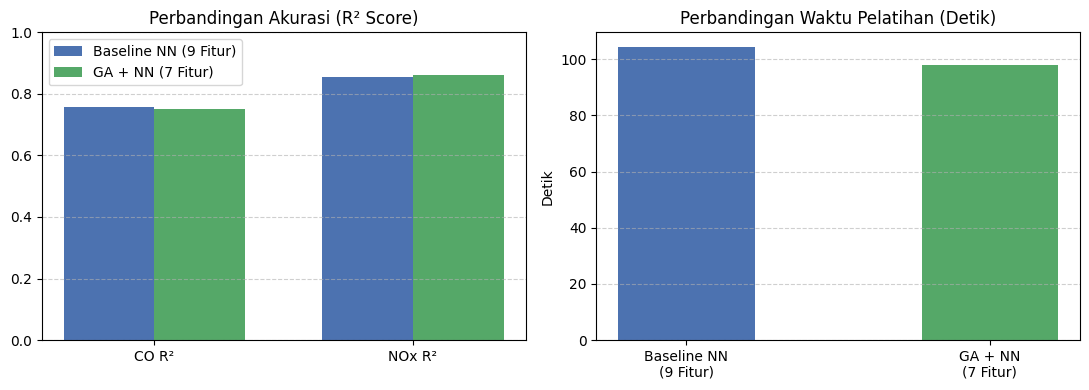

In [5]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# 1. Perbandingan R² (CO & NOx)
label_target = ['CO R²', 'NOx R²']
base_r2 = [df_perbandingan.loc[0, 'CO R²'], df_perbandingan.loc[0, 'NOx R²']]
ga_r2   = [df_perbandingan.loc[1, 'CO R²'], df_perbandingan.loc[1, 'NOx R²']]

x = np.arange(len(label_target))
width = 0.35

axes[0].bar(x - width/2, base_r2, width, label='Baseline NN (9 Fitur)', color='#4C72B0')
axes[0].bar(x + width/2, ga_r2, width, label='GA + NN (7 Fitur)', color='#55A868')
axes[0].set_title('Perbandingan Akurasi (R² Score)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(label_target)
axes[0].set_ylim(0, 1.0)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# 2. Perbandingan Waktu Komputasi
models = ['Baseline NN\n(9 Fitur)', 'GA + NN\n(7 Fitur)']
waktu  = [df_perbandingan.loc[0, 'Waktu Latih (detik)'], df_perbandingan.loc[1, 'Waktu Latih (detik)']]

axes[1].bar(models, waktu, width=0.45, color=['#4C72B0', '#55A868'])
axes[1].set_title('Perbandingan Waktu Pelatihan (Detik)')
axes[1].set_ylabel('Detik')
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('ga_vs_baseline.png', dpi=150)
plt.show()